# CA1 – Task 1: Retail Performance Analytics
**DL836 Y4 – Research & Analytics | Data Analytics for Business**

**Scenario:** Data Analytics Consultant reporting to the **Marketing Director**.

**Objective:** Identify the factors that drive retail sales performance and build predictive models that can forecast `SalesRevenue`.

**Dataset:** `Retail_stores.csv` – 5,100 store-period records across 100 stores, 4 regions, 3 store types and 4 seasons.

| Section | Contents |
|---|---|
| 1 | Setup & data loading |
| 2 | Data preparation & quality assessment (missing values, duplicates, outliers) |
| 3 | Feature engineering (7 new features) |
| 4 | Exploratory data analysis (6 GroupBy analyses, Top 5 stores/regions) |
| 5 | Pivot tables & correlation analysis |
| 6 | Predictive analytics (Linear Regression, Decision Tree, Random Forest, Gradient Boosting + K-Means segmentation) |
| 7 | Feature importance & marketing insights (evidence for Task 3) |
| 8 | Summary of outputs |

## 1. Setup & Data Loading

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110

DATA_PATH = "../data/Retail_stores.csv"
FIG_DIR = "../outputs/figures/"
TABLE_DIR = "../outputs/tables/"
RANDOM_STATE = 42

raw = pd.read_csv(DATA_PATH)
print("Shape:", raw.shape)
raw.head()

Shape: (5100, 14)


,StoreID,Region,StoreType,MarketingSpend,Footfall,OnlineTraffic,StaffHours,DiscountRate,CustomerSatisfaction,InventoryAvailability,CompetitorDistance,PreviousMonthSales,Season,SalesRevenue
0,1051,North,Mall,"3,112.97","1,194.76","5,995.25",295.91,19.07,NaN,81.00,12.97,"50,135.82",Summer,"249,522.51"
1,1092,North,Town,"6,318.71","1,893.94","9,399.31",303.88,4.22,59.67,83.52,17.89,"46,881.42",Winter,"362,564.72"
2,1014,North,Retail Park,"4,934.11","1,280.26","13,337.94",347.68,4.26,76.55,95.34,19.87,"50,382.03",Winter,"315,300.65"
3,1071,North,Town,"6,631.18",728.99,"6,510.31",337.10,38.56,85.94,90.22,11.56,"48,063.98",Winter,"360,506.70"
4,1060,South,Town,"5,262.87",602.07,"10,394.07",327.64,39.17,67.33,76.20,7.29,"44,882.50",Autumn,"323,011.58"


In [2]:
# Structure and data types
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 5100 entries, 0 to 5099
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   StoreID                5100 non-null   int64  
 1   Region                 5100 non-null   str    
 2   StoreType              5100 non-null   str    
 3   MarketingSpend         4747 non-null   float64
 4   Footfall               5100 non-null   float64
 5   OnlineTraffic          4745 non-null   float64
 6   StaffHours             5100 non-null   float64
 7   DiscountRate           5100 non-null   float64
 8   CustomerSatisfaction   4748 non-null   float64
 9   InventoryAvailability  4742 non-null   float64
 10  CompetitorDistance     5100 non-null   float64
 11  PreviousMonthSales     5100 non-null   float64
 12  Season                 5100 non-null   str    
 13  SalesRevenue           5100 non-null   float64
dtypes: float64(10), int64(1), str(3)
memory usage: 557.9 KB


In [3]:
# Summary statistics for every column
raw.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
StoreID,"5,100.00",NaN,NaN,NaN,"1,048.83",28.98,"1,000.00","1,024.00","1,048.00","1,074.00","1,099.00"
Region,5100,4,South,1298,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StoreType,5100,3,Mall,1758,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MarketingSpend,"4,747.00",NaN,NaN,NaN,"5,303.37","3,777.19",250.00,"3,976.51","5,002.19","6,059.86","64,121.81"
Footfall,"5,100.00",NaN,NaN,NaN,"1,203.78",351.05,100.00,964.95,"1,211.18","1,444.26","2,522.12"
OnlineTraffic,"4,745.00",NaN,NaN,NaN,"8,546.86","2,509.86",500.00,"6,850.05","8,498.92","10,247.97","18,016.79"
StaffHours,"5,100.00",NaN,NaN,NaN,350.18,79.80,74.67,293.49,349.85,403.38,645.00
DiscountRate,"5,100.00",NaN,NaN,NaN,19.99,11.54,0.01,10.06,20.09,29.90,39.97
CustomerSatisfaction,"4,748.00",NaN,NaN,NaN,75.02,9.83,39.78,68.19,74.74,81.67,100.00
InventoryAvailability,"4,742.00",NaN,NaN,NaN,84.94,7.82,58.00,79.48,85.01,90.54,100.00


In [4]:
# Categorical columns – check the levels are clean and consistent
for col in ["Region", "StoreType", "Season"]:
    print(col, raw[col].value_counts().to_dict())
print("Unique stores:", raw["StoreID"].nunique())

Region {'South': 1298, 'East': 1295, 'West': 1259, 'North': 1248}
StoreType {'Mall': 1758, 'Retail Park': 1673, 'Town': 1669}
Season {'Spring': 1315, 'Winter': 1292, 'Autumn': 1255, 'Summer': 1238}
Unique stores: 100


In [5]:
# Consistency check: is each StoreID always in the same Region and StoreType?
store_consistency = raw.groupby("StoreID").agg(Records=("Region", "size"),
                                               UniqueRegions=("Region", "nunique"),
                                               UniqueStoreTypes=("StoreType", "nunique"))
store_consistency.describe().loc[["min", "mean", "max"]]

,Records,UniqueRegions,UniqueStoreTypes
min,32.00,4.00,3.00
mean,51.00,4.00,3.00
max,72.00,4.00,3.00


**Data quality issue – StoreID:** every StoreID appears in **all 4 regions and all 3 store types**. A StoreID is therefore not one physical location: it may be a store number reused across regional networks, or a coding error. Store-level analysis below groups by `StoreID` alone (about 50 records per store), and location-level analysis uses **Region × StoreType**. This limitation should be raised with the data owner.

## 2. Data Preparation & Quality Assessment
### 2.1 Missing value analysis

In [6]:
missing = pd.DataFrame({
    "MissingCount": raw.isna().sum(),
    "MissingPct": (raw.isna().mean() * 100).round(2),
})
missing = missing[missing["MissingCount"] > 0].sort_values("MissingCount", ascending=False)
missing

,MissingCount,MissingPct
InventoryAvailability,358,7.02
OnlineTraffic,355,6.96
MarketingSpend,353,6.92
CustomerSatisfaction,352,6.90


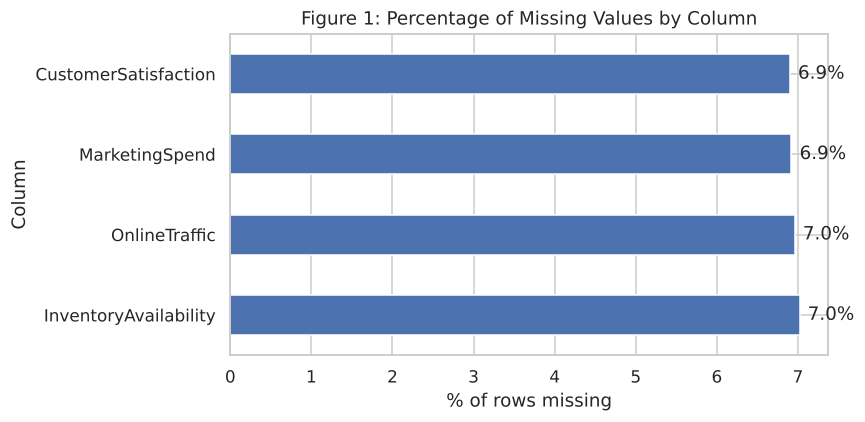

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
missing["MissingPct"].plot(kind="barh", ax=ax, color="#4C72B0")
ax.set_title("Figure 1: Percentage of Missing Values by Column")
ax.set_xlabel("% of rows missing")
ax.set_ylabel("Column")
for i, v in enumerate(missing["MissingPct"]):
    ax.text(v + 0.1, i, f"{v:.1f}%", va="center")
plt.tight_layout()
plt.savefig(FIG_DIR + "t1_fig01_missing_values.png", bbox_inches="tight")
plt.show()

In [8]:
# Are missing values concentrated in particular rows? (rows with >1 missing field)
print("Rows with at least one missing value:", raw.isna().any(axis=1).sum())
print("Rows with more than one missing value:", (raw.isna().sum(axis=1) > 1).sum())
# Is missingness related to sales? Compare revenue for rows with/without missing MarketingSpend
print(raw.groupby(raw["MarketingSpend"].isna())["SalesRevenue"].mean().rename({False: "Present", True: "Missing"}))

Rows with at least one missing value: 1269
Rows with more than one missing value: 141
MarketingSpend
Present   314,653.50
Missing   318,475.23
Name: SalesRevenue, dtype: float64


### 2.2 Duplicate analysis

In [9]:
dup_count = raw.duplicated().sum()
print(f"Exact duplicate rows: {dup_count} ({dup_count / len(raw):.2%} of data)")
raw[raw.duplicated(keep=False)].sort_values(["StoreID", "SalesRevenue"]).head(6)

Exact duplicate rows: 100 (1.96% of data)


,StoreID,Region,StoreType,MarketingSpend,Footfall,OnlineTraffic,StaffHours,DiscountRate,CustomerSatisfaction,InventoryAvailability,CompetitorDistance,PreviousMonthSales,Season,SalesRevenue
2215,1000,South,Town,"3,496.84","1,118.59","6,486.61",336.24,18.58,65.74,87.81,1.22,"43,769.55",Summer,"268,776.16"
5067,1000,South,Town,"3,496.84","1,118.59","6,486.61",336.24,18.58,65.74,87.81,1.22,"43,769.55",Summer,"268,776.16"
705,1000,West,Mall,"4,487.53",664.61,"11,532.52",516.06,24.68,74.54,86.91,11.71,"43,952.09",Autumn,"306,124.55"
5004,1000,West,Mall,"4,487.53",664.61,"11,532.52",516.06,24.68,74.54,86.91,11.71,"43,952.09",Autumn,"306,124.55"
486,1000,West,Retail Park,"4,738.45","1,083.37","7,724.19",364.71,18.25,78.87,88.19,11.26,"48,768.43",Spring,"308,125.42"
5029,1000,West,Retail Park,"4,738.45","1,083.37","7,724.19",364.71,18.25,78.87,88.19,11.26,"48,768.43",Spring,"308,125.42"


In [10]:
df = raw.drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (5000, 14)


### 2.3 Outlier investigation (IQR method)
An observation is flagged as an outlier if it is below Q1 − 1.5×IQR or above Q3 + 1.5×IQR. Values beyond **3×IQR** are flagged as *extreme*.

In [11]:
num_cols = ["MarketingSpend", "Footfall", "OnlineTraffic", "StaffHours", "DiscountRate",
            "CustomerSatisfaction", "InventoryAvailability", "CompetitorDistance",
            "PreviousMonthSales", "SalesRevenue"]

def iqr_summary(data, cols):
    rows = []
    for c in cols:
        q1, q3 = data[c].quantile([0.25, 0.75])
        iqr = q3 - q1
        lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        ext_hi = q3 + 3 * iqr
        rows.append({
            "Column": c, "Q1": q1, "Q3": q3, "LowerFence": lo, "UpperFence": hi,
            "Outliers": int(((data[c] < lo) | (data[c] > hi)).sum()),
            "ExtremeHigh(>3xIQR)": int((data[c] > ext_hi).sum()),
            "Min": data[c].min(), "Max": data[c].max(),
        })
    return pd.DataFrame(rows).set_index("Column")

outlier_table = iqr_summary(df, num_cols)
outlier_table

,Q1,Q3,LowerFence,UpperFence,Outliers,ExtremeHigh(>3xIQR),Min,Max
Column,,,,,,,,
MarketingSpend,"3,970.56","6,060.01",836.40,"9,194.17",71,44,250.00,"64,121.81"
Footfall,964.10,"1,444.65",243.26,"2,165.48",37,0,100.00,"2,522.12"
OnlineTraffic,"6,851.82","10,248.68","1,756.54","15,343.97",27,0,500.00,"18,016.79"
StaffHours,293.17,403.38,127.84,568.71,26,0,74.67,645.00
DiscountRate,10.04,29.87,-19.71,59.61,0,0,0.01,39.97
CustomerSatisfaction,68.14,81.68,47.83,101.99,13,0,39.78,100.00
InventoryAvailability,79.46,90.57,62.79,107.23,9,0,58.00,100.00
CompetitorDistance,5.51,15.24,-9.08,29.83,0,0,0.50,20.00
PreviousMonthSales,"38,787.32","50,953.27","20,538.38","69,202.21",30,0,"14,538.80","73,774.72"


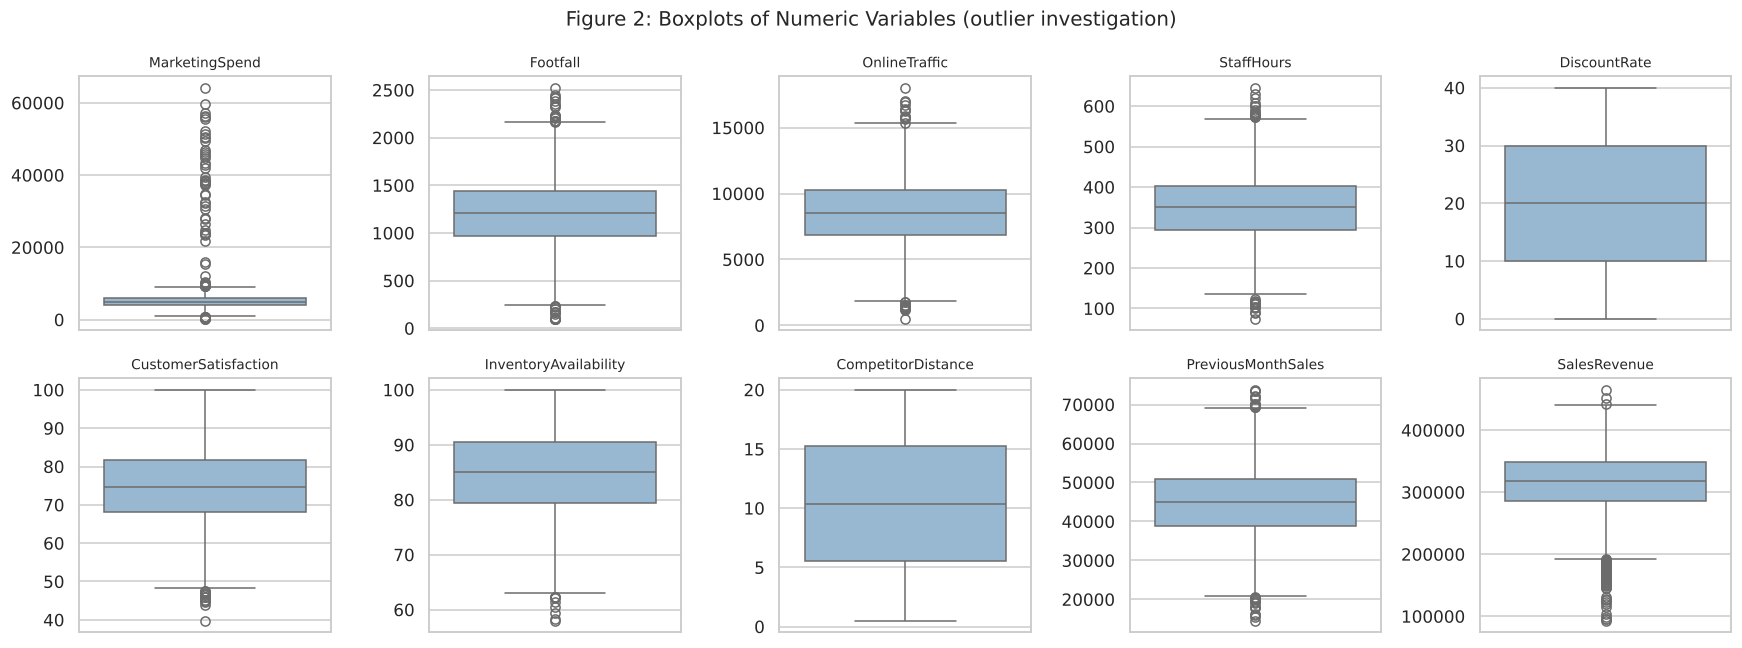

In [12]:
fig, axes = plt.subplots(2, 5, figsize=(16, 6))
for ax, c in zip(axes.ravel(), num_cols):
    sns.boxplot(y=df[c], ax=ax, color="#8EBAD9")
    ax.set_title(c, fontsize=9)
    ax.set_ylabel("")
fig.suptitle("Figure 2: Boxplots of Numeric Variables (outlier investigation)", fontsize=13)
plt.tight_layout()
plt.savefig(FIG_DIR + "t1_fig02_boxplots.png", bbox_inches="tight")
plt.show()

In [13]:
# MarketingSpend has a small number of extreme values (>3x IQR). Do these stores earn more?
q1, q3 = df["MarketingSpend"].quantile([0.25, 0.75])
extreme_cut = q3 + 3 * (q3 - q1)
extreme = df["MarketingSpend"] > extreme_cut
print(f"Extreme MarketingSpend cut-off: €{extreme_cut:,.0f}")
print(f"Extreme rows: {extreme.sum()}")
print("Median MarketingSpend (normal rows): €{:,.0f}".format(df.loc[~extreme, "MarketingSpend"].median()))
print("Median MarketingSpend (extreme rows): €{:,.0f}".format(df.loc[extreme, "MarketingSpend"].median()))
print("Mean SalesRevenue (normal rows):  €{:,.0f}".format(df.loc[~extreme, "SalesRevenue"].mean()))
print("Mean SalesRevenue (extreme rows): €{:,.0f}".format(df.loc[extreme, "SalesRevenue"].mean()))

Extreme MarketingSpend cut-off: €12,328
Extreme rows: 44
Median MarketingSpend (normal rows): €4,977
Median MarketingSpend (extreme rows): €38,363
Mean SalesRevenue (normal rows):  €314,819
Mean SalesRevenue (extreme rows): €310,839


**Outlier treatment decisions**

* **MarketingSpend extreme values** (>3×IQR, roughly 5–10× the typical spend) do *not* come with a matching rise in revenue, which suggests data-entry errors (e.g. an extra digit). These are set to missing and imputed with the rest of the missing values, so they don't distort the models.
* **Other outliers** (Footfall, OnlineTraffic, StaffHours, SalesRevenue) lie within a plausible business range and are kept: they reflect genuinely busy or quiet periods. The target variable `SalesRevenue` is never altered.

In [14]:
df["MarketingSpend_extreme_flag"] = extreme.astype(int)
df.loc[extreme, "MarketingSpend"] = np.nan

### 2.4 Missing value treatment
Missing values are ~7% per column and occur independently (rows rarely have more than one missing value), so dropping rows would lose ~25% of the data. Instead, numeric gaps are filled with the **median for the same StoreType and Region**, which is robust to skew and keeps the typical level for comparable stores.

In [15]:
impute_cols = ["MarketingSpend", "OnlineTraffic", "CustomerSatisfaction", "InventoryAvailability"]
before = df[impute_cols].isna().sum()
# Keep a flag of which rows had MarketingSpend filled in, so model errors can be checked later
df["MarketingSpend_imputed"] = df["MarketingSpend"].isna().astype(int)

for c in impute_cols:
    df[c] = df[c].fillna(df.groupby(["StoreType", "Region"])[c].transform("median"))
    df[c] = df[c].fillna(df[c].median())  # fallback (not expected to be needed)

pd.DataFrame({"MissingBefore": before, "MissingAfter": df[impute_cols].isna().sum()})

,MissingBefore,MissingAfter
MarketingSpend,394,0
OnlineTraffic,350,0
CustomerSatisfaction,350,0
InventoryAvailability,350,0


### 2.5 Data quality summary

In [16]:
dq_summary = pd.DataFrame({
    "Check": ["Rows loaded", "Exact duplicates removed", "Rows after de-duplication",
              "Missing cells (original)", "Extreme MarketingSpend values re-coded as missing",
              "Missing cells after imputation", "Categorical inconsistencies"],
    "Result": [len(raw), dup_count, len(df), int(raw.isna().sum().sum()), int(extreme.sum()),
               int(df[impute_cols].isna().sum().sum()), "None – Region/StoreType/Season are clean"],
})
dq_summary.to_csv(TABLE_DIR + "t1_data_quality_summary.csv", index=False)
dq_summary

,Check,Result
0,Rows loaded,5100
1,Exact duplicates removed,100
2,Rows after de-duplication,5000
3,Missing cells (original),1418
4,Extreme MarketingSpend values re-coded as missing,44
5,Missing cells after imputation,0
6,Categorical inconsistencies,None – Region/StoreType/Season are clean


## 3. Feature Engineering
The dataset has no date column, so the new features combine existing columns to create business KPIs.

| # | Feature | Formula | Purpose | Used in model? |
|---|---|---|---|---|
| 1 | `TotalTraffic` | Footfall + OnlineTraffic | Overall customer reach | ✔ |
| 2 | `OnlineShare` | OnlineTraffic / TotalTraffic | Channel mix (digital vs in-store) | ✔ |
| 3 | `MarketingPerVisitor` | MarketingSpend / TotalTraffic | Marketing intensity per visitor | ✔ |
| 4 | `SalesPerStaffHour` | PreviousMonthSales / StaffHours | Prior staff productivity | ✔ |
| 5 | `MarketingROI` | SalesRevenue / MarketingSpend | Revenue earned per €1 of marketing | ✘ (uses target) |
| 6 | `RevenuePerVisitor` | SalesRevenue / TotalTraffic | Conversion value per visitor | ✘ (uses target) |
| 7 | `MarketingBand`, `DiscountBand`, `CompetitorBand` | Quartile/range bins | Easier segment comparison | EDA only |

Features 5 and 6 contain the target variable, so they are only used for EDA. Putting them into a model would cause **data leakage**.

In [17]:
df["TotalTraffic"] = df["Footfall"] + df["OnlineTraffic"]
df["OnlineShare"] = df["OnlineTraffic"] / df["TotalTraffic"]
df["MarketingPerVisitor"] = df["MarketingSpend"] / df["TotalTraffic"]
df["SalesPerStaffHour"] = df["PreviousMonthSales"] / df["StaffHours"]
df["MarketingROI"] = df["SalesRevenue"] / df["MarketingSpend"]
df["RevenuePerVisitor"] = df["SalesRevenue"] / df["TotalTraffic"]

df["MarketingBand"] = pd.qcut(df["MarketingSpend"], 4, labels=["Q1 Low", "Q2", "Q3", "Q4 High"])
df["DiscountBand"] = pd.cut(df["DiscountRate"], bins=[0, 10, 20, 30, 40],
                            labels=["0-10%", "10-20%", "20-30%", "30-40%"], include_lowest=True)
df["CompetitorBand"] = pd.cut(df["CompetitorDistance"], bins=[0, 5, 10, 15, 20],
                              labels=["<5km", "5-10km", "10-15km", "15-20km"], include_lowest=True)

df[["TotalTraffic", "OnlineShare", "MarketingPerVisitor", "SalesPerStaffHour",
    "MarketingROI", "RevenuePerVisitor", "MarketingBand", "DiscountBand", "CompetitorBand"]].head()

,TotalTraffic,OnlineShare,MarketingPerVisitor,SalesPerStaffHour,MarketingROI,RevenuePerVisitor,MarketingBand,DiscountBand,CompetitorBand
0,"7,190.01",0.83,0.43,169.43,80.16,34.70,Q1 Low,10-20%,10-15km
1,"11,293.25",0.83,0.56,154.28,57.38,32.10,Q4 High,0-10%,15-20km
2,"14,618.21",0.91,0.34,144.91,63.90,21.57,Q2,0-10%,15-20km
3,"7,239.30",0.90,0.92,142.58,54.37,49.80,Q4 High,30-40%,10-15km
4,"10,996.15",0.95,0.48,136.99,61.38,29.37,Q3,30-40%,5-10km


In [18]:
df[["TotalTraffic", "OnlineShare", "MarketingPerVisitor", "SalesPerStaffHour",
    "MarketingROI", "RevenuePerVisitor"]].describe().T

,count,mean,std,min,25%,50%,75%,max
TotalTraffic,"5,000.00","9,753.12","2,452.55","1,835.61","8,193.80","9,726.05","11,303.74","19,710.12"
OnlineShare,"5,000.00",0.87,0.05,0.27,0.84,0.88,0.90,0.99
MarketingPerVisitor,"5,000.00",0.55,0.26,0.02,0.39,0.51,0.66,2.77
SalesPerStaffHour,"5,000.00",136.25,46.73,29.48,105.79,128.90,158.30,703.75
MarketingROI,"5,000.00",67.09,17.32,14.87,57.84,63.82,71.91,397.62
RevenuePerVisitor,"5,000.00",34.82,12.90,8.28,26.96,32.34,39.18,164.95


## 4. Exploratory Data Analysis
### 4.1 Summary statistics (cleaned data)

In [19]:
df[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
MarketingSpend,"5,000.00","4,983.56","1,453.58",250.00,"4,067.72","4,980.75","5,922.35","12,092.42"
Footfall,"5,000.00","1,204.04",351.29,100.00,964.10,"1,211.46","1,444.65","2,522.12"
OnlineTraffic,"5,000.00","8,549.08","2,419.59",500.00,"7,002.72","8,487.75","10,100.62","18,016.79"
StaffHours,"5,000.00",350.04,79.83,74.67,293.17,349.66,403.38,645.00
DiscountRate,"5,000.00",19.95,11.54,0.01,10.04,20.03,29.87,39.97
CustomerSatisfaction,"5,000.00",74.96,9.48,39.78,68.68,74.68,81.10,100.00
InventoryAvailability,"5,000.00",84.94,7.55,58.00,79.86,85.07,90.07,100.00
CompetitorDistance,"5,000.00",10.30,5.63,0.50,5.51,10.32,15.24,20.00
PreviousMonthSales,"5,000.00","44,933.32","8,926.93","14,538.80","38,787.32","44,881.61","50,953.27","73,774.72"
SalesRevenue,"5,000.00","314,784.35","48,340.38","92,957.26","285,732.53","318,174.02","348,441.04","465,006.45"


### 4.2 GroupBy 1 – Regional performance

In [20]:
gb_region = (df.groupby("Region")
               .agg(Records=("SalesRevenue", "size"),
                    TotalRevenue=("SalesRevenue", "sum"),
                    AvgRevenue=("SalesRevenue", "mean"),
                    AvgMarketingSpend=("MarketingSpend", "mean"),
                    AvgMarketingROI=("MarketingROI", "median"),
                    AvgSatisfaction=("CustomerSatisfaction", "mean"))
               .sort_values("TotalRevenue", ascending=False))
gb_region["RevenueShare%"] = gb_region["TotalRevenue"] / gb_region["TotalRevenue"].sum() * 100
gb_region.to_csv(TABLE_DIR + "t1_groupby_region.csv")
gb_region

,Records,TotalRevenue,AvgRevenue,AvgMarketingSpend,AvgMarketingROI,AvgSatisfaction,RevenueShare%
Region,,,,,,,
South,1276,"403,383,952.42","316,131.62","4,991.00",64.36,74.87,25.63
East,1264,"395,635,862.35","313,003.06","4,923.08",64.20,74.87,25.14
West,1237,"391,621,618.09","316,589.83","5,045.56",63.04,74.90,24.88
North,1223,"383,280,332.78","313,393.57","4,975.59",63.67,75.23,24.35


### 4.3 GroupBy 2 – Seasonal performance

In [21]:
season_order = ["Spring", "Summer", "Autumn", "Winter"]
gb_season = (df.groupby("Season")
               .agg(AvgRevenue=("SalesRevenue", "mean"),
                    TotalRevenue=("SalesRevenue", "sum"),
                    AvgMarketingSpend=("MarketingSpend", "mean"),
                    AvgDiscount=("DiscountRate", "mean"),
                    AvgFootfall=("Footfall", "mean"),
                    AvgOnlineTraffic=("OnlineTraffic", "mean"))
               .reindex(season_order))
gb_season.to_csv(TABLE_DIR + "t1_groupby_season.csv")
gb_season

,AvgRevenue,TotalRevenue,AvgMarketingSpend,AvgDiscount,AvgFootfall,AvgOnlineTraffic
Season,,,,,,
Spring,"312,312.24","402,258,163.68","4,917.30",19.88,"1,211.61","8,516.41"
Summer,"316,697.77","382,570,905.20","5,053.79",20.09,"1,215.70","8,546.58"
Autumn,"313,910.40","386,423,707.46","4,943.71",19.89,"1,204.11","8,591.53"
Winter,"316,315.00","402,668,989.30","5,022.49",19.95,"1,185.25","8,543.47"


### 4.4 GroupBy 3 – Store type performance

In [22]:
gb_type = (df.groupby("StoreType")
             .agg(AvgRevenue=("SalesRevenue", "mean"),
                  TotalRevenue=("SalesRevenue", "sum"),
                  AvgMarketingSpend=("MarketingSpend", "mean"),
                  MedianMarketingROI=("MarketingROI", "median"),
                  AvgRevenuePerVisitor=("RevenuePerVisitor", "mean"),
                  AvgOnlineShare=("OnlineShare", "mean"))
             .sort_values("AvgRevenue", ascending=False))
gb_type.to_csv(TABLE_DIR + "t1_groupby_storetype.csv")
gb_type

,AvgRevenue,TotalRevenue,AvgMarketingSpend,MedianMarketingROI,AvgRevenuePerVisitor,AvgOnlineShare
StoreType,,,,,,
Mall,"315,832.57","545,442,840.67","5,001.05",64.06,34.74,0.87
Town,"314,964.12","512,761,593.89","5,005.48",63.19,34.83,0.87
Retail Park,"313,505.98","515,717,331.08","4,943.51",64.37,34.91,0.87


### 4.5 GroupBy 4 – Store-level performance (Top 5 and Bottom 5 stores)

In [23]:
gb_store = (df.groupby("StoreID")
              .agg(Records=("SalesRevenue", "size"),
                   AvgRevenue=("SalesRevenue", "mean"),
                   TotalRevenue=("SalesRevenue", "sum"),
                   AvgMarketingSpend=("MarketingSpend", "mean"),
                   MedianMarketingROI=("MarketingROI", "median"),
                   AvgSatisfaction=("CustomerSatisfaction", "mean"))
              .sort_values("TotalRevenue", ascending=False))
gb_store.to_csv(TABLE_DIR + "t1_groupby_store.csv")
print("Top 5 stores by TOTAL revenue")
display(gb_store.head(5))
print("Top 5 stores by AVERAGE revenue per record")
display(gb_store.sort_values("AvgRevenue", ascending=False).head(5))
print("Bottom 5 stores by AVERAGE revenue per record")
display(gb_store.sort_values("AvgRevenue").head(5))

Top 5 stores by TOTAL revenue


,Records,AvgRevenue,TotalRevenue,AvgMarketingSpend,MedianMarketingROI,AvgSatisfaction
StoreID,,,,,,
1020,68,"314,140.86","21,361,578.58","4,896.16",64.76,74.53
1016,65,"321,876.23","20,921,954.99","5,092.72",62.06,75.07
1046,68,"306,522.20","20,843,509.57","4,715.37",66.16,74.26
1061,63,"321,145.14","20,232,143.78","5,201.06",62.42,74.34
1059,61,"330,532.75","20,162,497.50","5,400.47",61.93,75.14


Top 5 stores by AVERAGE revenue per record


,Records,AvgRevenue,TotalRevenue,AvgMarketingSpend,MedianMarketingROI,AvgSatisfaction
StoreID,,,,,,
1070,33,"332,861.08","10,984,415.67","5,619.02",59.49,76.71
1030,31,"330,772.03","10,253,933.06","5,437.11",61.88,72.66
1059,61,"330,532.75","20,162,497.50","5,400.47",61.93,75.14
1032,61,"329,365.05","20,091,267.88","5,520.43",60.33,73.98
1071,48,"327,829.26","15,735,804.44","5,319.74",60.89,75.82


Bottom 5 stores by AVERAGE revenue per record


,Records,AvgRevenue,TotalRevenue,AvgMarketingSpend,MedianMarketingROI,AvgSatisfaction
StoreID,,,,,,
1066,45,"293,118.75","13,190,343.89","4,345.59",67.90,76.50
1056,49,"301,614.34","14,779,102.80","4,685.12",66.53,74.09
1019,47,"302,695.83","14,226,704.15","4,591.13",67.11,76.33
1077,46,"303,369.24","13,954,985.20","4,678.81",65.91,75.21
1068,48,"303,884.25","14,586,444.22","4,648.11",65.82,75.84


In [24]:
# Location level: Top 5 Region x StoreType combinations
gb_location = (df.groupby(["Region", "StoreType"])
                 .agg(Records=("SalesRevenue", "size"),
                      AvgRevenue=("SalesRevenue", "mean"),
                      TotalRevenue=("SalesRevenue", "sum"),
                      MedianMarketingROI=("MarketingROI", "median"))
                 .sort_values("AvgRevenue", ascending=False)
                 .reset_index())
print("Top 5 Region x StoreType locations by average revenue")
gb_location.head(5)

Top 5 Region x StoreType locations by average revenue


,Region,StoreType,Records,AvgRevenue,TotalRevenue,MedianMarketingROI
0,South,Mall,423,"321,136.88","135,840,902.32",64.21
1,West,Town,383,"317,977.87","121,785,525.13",62.21
2,West,Retail Park,418,"317,012.43","132,511,194.29",62.85
3,West,Mall,436,"314,965.36","137,324,898.67",64.17
4,East,Town,399,"314,461.46","125,470,124.36",63.56


### 4.6 GroupBy 5 – Marketing spend band (is more marketing linked to more revenue?)

In [25]:
gb_mkt = (df.groupby("MarketingBand", observed=True)
            .agg(MinSpend=("MarketingSpend", "min"),
                 MaxSpend=("MarketingSpend", "max"),
                 AvgSpend=("MarketingSpend", "mean"),
                 AvgRevenue=("SalesRevenue", "mean"),
                 MedianROI=("MarketingROI", "median"),
                 Records=("SalesRevenue", "size")))
gb_mkt["RevenueUpliftVsQ1%"] = (gb_mkt["AvgRevenue"] / gb_mkt["AvgRevenue"].iloc[0] - 1) * 100
gb_mkt.to_csv(TABLE_DIR + "t1_groupby_marketing_band.csv")
gb_mkt

,MinSpend,MaxSpend,AvgSpend,AvgRevenue,MedianROI,Records,RevenueUpliftVsQ1%
MarketingBand,,,,,,,
Q1 Low,250.00,"4,067.51","3,129.18","254,180.62",79.63,1250,0.00
Q2,"4,067.79","4,980.75","4,617.98","306,809.56",66.81,1298,20.71
Q3,"4,983.20","5,922.25","5,383.19","329,673.21",60.99,1202,29.70
Q4 High,"5,922.68","12,092.42","6,833.26","369,351.99",54.77,1250,45.31


### 4.7 GroupBy 6 – Discount band and competitor distance

In [26]:
gb_discount = (df.groupby("DiscountBand", observed=True)
                 .agg(AvgRevenue=("SalesRevenue", "mean"),
                      AvgFootfall=("Footfall", "mean"),
                      AvgSatisfaction=("CustomerSatisfaction", "mean"),
                      Records=("SalesRevenue", "size")))
gb_comp = (df.groupby("CompetitorBand", observed=True)
             .agg(AvgRevenue=("SalesRevenue", "mean"), Records=("SalesRevenue", "size")))
display(gb_discount)
display(gb_comp)

,AvgRevenue,AvgFootfall,AvgSatisfaction,Records
DiscountBand,,,,
0-10%,"315,354.14","1,211.23",74.57,1243
10-20%,"315,316.17","1,194.46",74.65,1251
20-30%,"314,573.68","1,189.44",75.17,1279
30-40%,"313,884.52","1,221.74",75.47,1227


,AvgRevenue,Records
CompetitorBand,,
<5km,"314,484.59",1129
5-10km,"314,104.65",1284
10-15km,"313,810.42",1275
15-20km,"316,653.97",1312


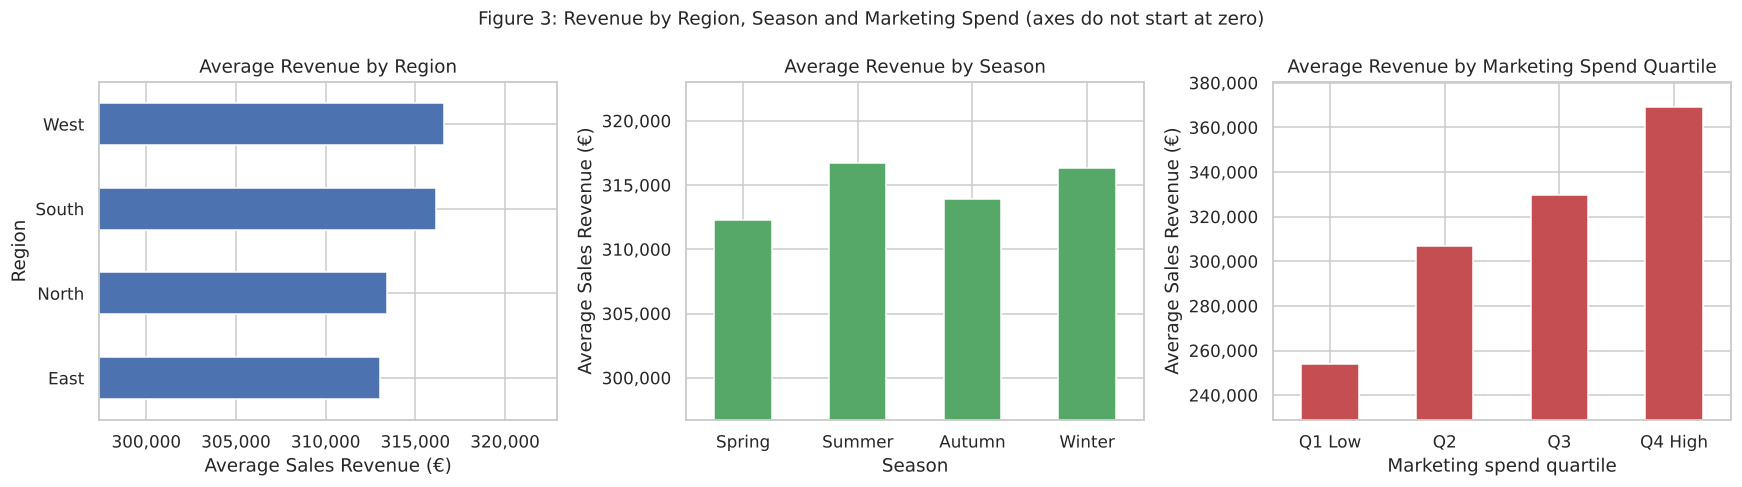

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

gb_region["AvgRevenue"].sort_values().plot(kind="barh", ax=axes[0], color="#4C72B0")
axes[0].set_title("Average Revenue by Region")
axes[0].set_xlabel("Average Sales Revenue (€)")
axes[0].set_xlim(gb_region["AvgRevenue"].min() * 0.95, gb_region["AvgRevenue"].max() * 1.02)

gb_season["AvgRevenue"].plot(kind="bar", ax=axes[1], color="#55A868")
axes[1].set_title("Average Revenue by Season")
axes[1].set_ylabel("Average Sales Revenue (€)")
axes[1].set_xlabel("Season")
axes[1].set_ylim(gb_season["AvgRevenue"].min() * 0.95, gb_season["AvgRevenue"].max() * 1.02)
axes[1].tick_params(axis="x", rotation=0)

gb_mkt["AvgRevenue"].plot(kind="bar", ax=axes[2], color="#C44E52")
axes[2].set_title("Average Revenue by Marketing Spend Quartile")
axes[2].set_ylabel("Average Sales Revenue (€)")
axes[2].set_xlabel("Marketing spend quartile")
axes[2].set_ylim(gb_mkt["AvgRevenue"].min() * 0.9, gb_mkt["AvgRevenue"].max() * 1.03)
axes[2].tick_params(axis="x", rotation=0)

fmt = plt.FuncFormatter(lambda x, _: f"{x:,.0f}")
axes[0].xaxis.set_major_formatter(fmt)
axes[1].yaxis.set_major_formatter(fmt)
axes[2].yaxis.set_major_formatter(fmt)
fig.suptitle("Figure 3: Revenue by Region, Season and Marketing Spend (axes do not start at zero)", fontsize=12)
plt.tight_layout()
plt.savefig(FIG_DIR + "t1_fig03_groupby_revenue.png", bbox_inches="tight")
plt.show()

### 4.8 Key EDA observations
* **Region, season and store type make very little difference.** Average revenue across regions ranges only from about €313k (East) to €317k (West), a gap of roughly 1%. Seasons (≈€312k–€317k) and store types (≈€314k–€316k) are similarly flat.
* **Marketing spend is the clear exception.** Records in the top marketing-spend quartile average ≈€369k revenue against ≈€254k in the bottom quartile, about **45% higher**.
* **Average return per € of marketing falls as spend rises:** median marketing ROI drops from ≈€80 per €1 (Q1) to ≈€55 per €1 (Q4).
* **Discount rate and competitor distance show no meaningful link to revenue.** Average revenue is almost identical across all discount and distance bands.
* **Store level:** stores 1020, 1016, 1046, 1061 and 1059 lead on total revenue, largely because they have the most records. On average revenue per record, the top stores (e.g. 1070, 1030, 1059) also have above-average marketing spend, while the bottom 5 all have below-average spend.

## 5. Pivot Tables & Correlation Analysis
### 5.1 Pivot Table 1 – Average revenue by Region × Season

In [28]:
pivot_region_season = pd.pivot_table(df, values="SalesRevenue", index="Region", columns="Season",
                                     aggfunc="mean", margins=True, margins_name="All")
pivot_region_season = pivot_region_season[season_order + ["All"]]
pivot_region_season.to_csv(TABLE_DIR + "t1_pivot_region_season.csv")
pivot_region_season

Season,Spring,Summer,Autumn,Winter,All
Region,,,,,
East,"307,968.69","316,408.55","313,321.32","313,991.55","313,003.06"
North,"310,260.47","316,902.82","309,091.31","317,496.67","313,393.57"
South,"313,945.50","315,662.61","319,476.29","315,945.10","316,131.62"
West,"316,503.13","317,836.85","314,179.35","317,842.71","316,589.83"
All,"312,312.24","316,697.77","313,910.40","316,315.00","314,784.35"


### 5.2 Pivot Table 2 – Median marketing ROI by Store Type × Marketing Spend quartile
Shows where each extra euro of marketing produces the most revenue.

In [29]:
pivot_roi = pd.pivot_table(df, values="MarketingROI", index="StoreType", columns="MarketingBand",
                           aggfunc="median", observed=True)
pivot_roi.to_csv(TABLE_DIR + "t1_pivot_storetype_marketing_roi.csv")
pivot_roi

MarketingBand,Q1 Low,Q2,Q3,Q4 High
StoreType,,,,
Mall,79.50,66.87,61.06,54.77
Retail Park,79.40,66.98,60.95,54.67
Town,80.04,66.53,60.87,54.96


### 5.3 Pivot Table 3 – Average revenue by Region × Store Type

In [30]:
pivot_region_type = pd.pivot_table(df, values="SalesRevenue", index="Region", columns="StoreType",
                                   aggfunc="mean", margins=True, margins_name="All")
pivot_region_type.to_csv(TABLE_DIR + "t1_pivot_region_storetype.csv")
pivot_region_type

StoreType,Mall,Retail Park,Town,All
Region,,,,
East,"313,006.85","311,613.54","314,461.46","313,003.06"
North,"314,394.77","311,640.82","314,143.85","313,393.57"
South,"321,136.88","313,737.07","313,572.96","316,131.62"
West,"314,965.36","317,012.43","317,977.87","316,589.83"
All,"315,832.57","313,505.98","314,964.12","314,784.35"


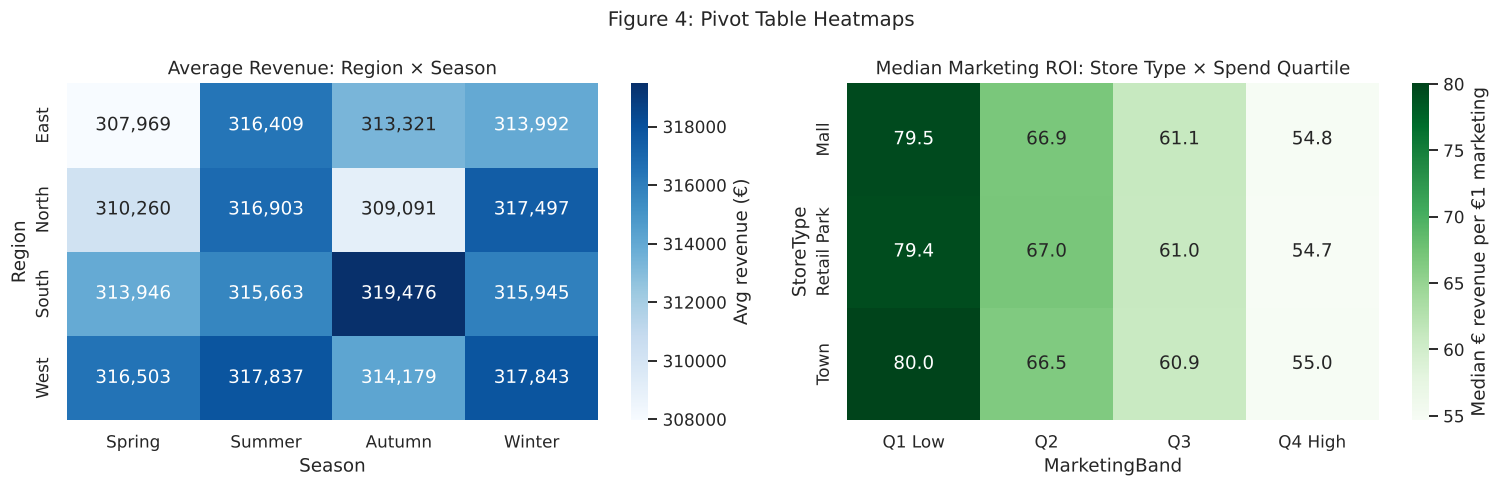

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.heatmap(pivot_region_season.drop(index="All", columns="All"), annot=True, fmt=",.0f",
            cmap="Blues", ax=axes[0], cbar_kws={"label": "Avg revenue (€)"})
axes[0].set_title("Average Revenue: Region × Season")
sns.heatmap(pivot_roi, annot=True, fmt=".1f", cmap="Greens", ax=axes[1],
            cbar_kws={"label": "Median € revenue per €1 marketing"})
axes[1].set_title("Median Marketing ROI: Store Type × Spend Quartile")
fig.suptitle("Figure 4: Pivot Table Heatmaps", fontsize=13)
plt.tight_layout()
plt.savefig(FIG_DIR + "t1_fig04_pivot_heatmaps.png", bbox_inches="tight")
plt.show()

### 5.4 Correlation analysis

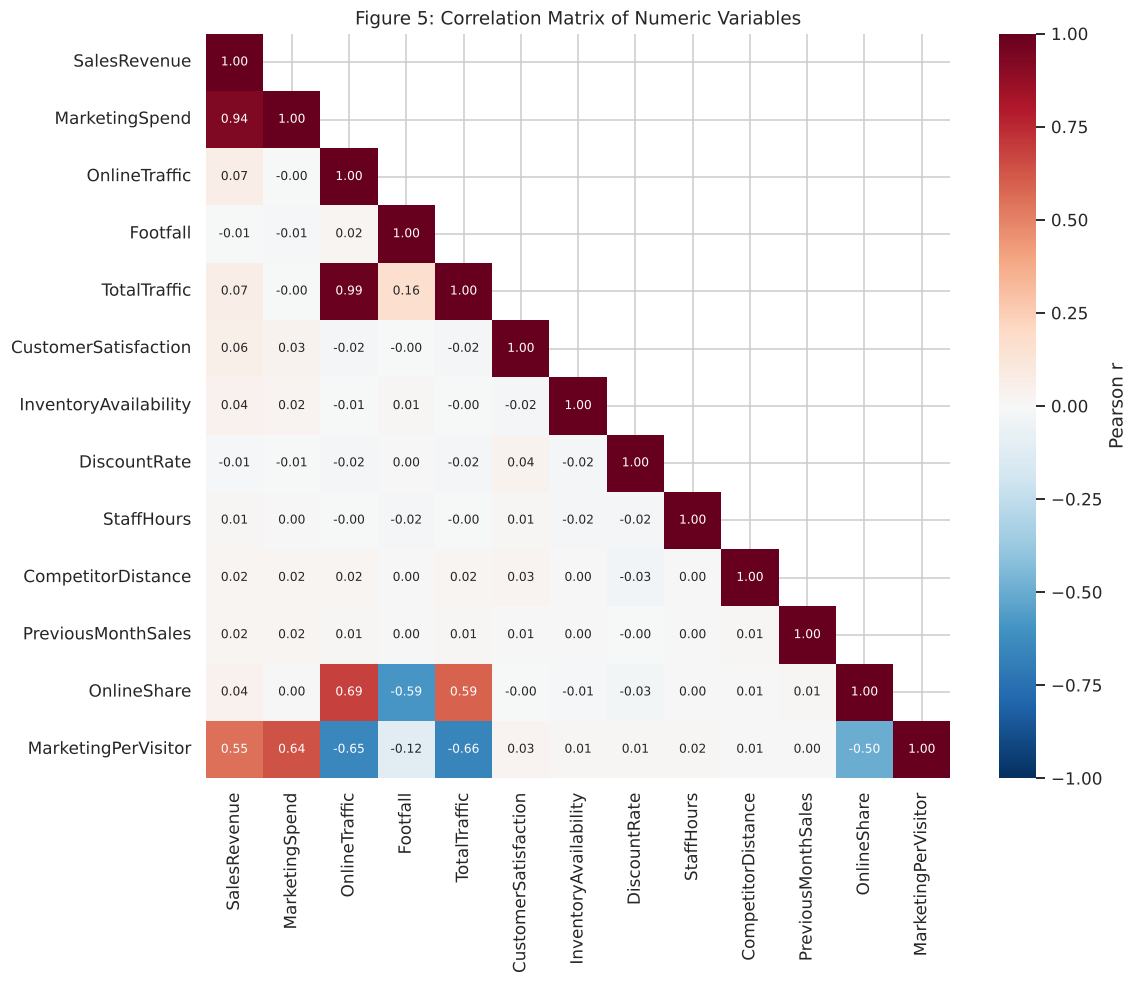

In [32]:
corr_cols = ["SalesRevenue", "MarketingSpend", "OnlineTraffic", "Footfall", "TotalTraffic",
             "CustomerSatisfaction", "InventoryAvailability", "DiscountRate", "StaffHours",
             "CompetitorDistance", "PreviousMonthSales", "OnlineShare", "MarketingPerVisitor"]
corr = df[corr_cols].corr()

fig, ax = plt.subplots(figsize=(11, 9))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            square=True, ax=ax, cbar_kws={"label": "Pearson r"}, annot_kws={"size": 8})
ax.set_title("Figure 5: Correlation Matrix of Numeric Variables")
plt.tight_layout()
plt.savefig(FIG_DIR + "t1_fig05_correlation_heatmap.png", bbox_inches="tight")
plt.show()

In [33]:
corr_target = corr["SalesRevenue"].drop("SalesRevenue").sort_values(key=abs, ascending=False)
corr_target.to_frame("Correlation with SalesRevenue")

,Correlation with SalesRevenue
MarketingSpend,0.94
MarketingPerVisitor,0.55
OnlineTraffic,0.07
TotalTraffic,0.07
CustomerSatisfaction,0.06
OnlineShare,0.04
InventoryAvailability,0.04
CompetitorDistance,0.02
PreviousMonthSales,0.02
DiscountRate,-0.01


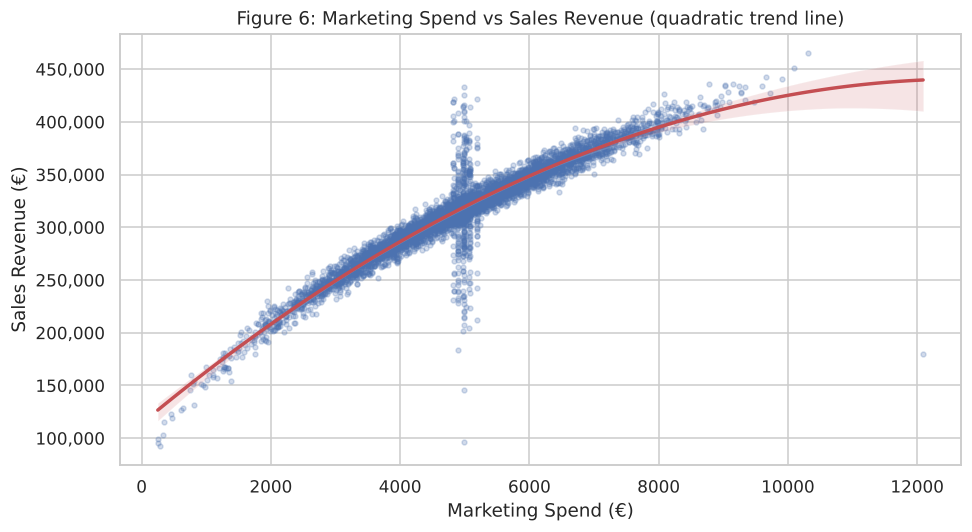

In [34]:
# Correlation alone only captures straight-line relationships; check the shape of the strongest one
fig, ax = plt.subplots(figsize=(9, 5))
sns.regplot(data=df, x="MarketingSpend", y="SalesRevenue", order=2, ax=ax,
            scatter_kws={"alpha": 0.25, "s": 10}, line_kws={"color": "#C44E52"})
ax.set_title("Figure 6: Marketing Spend vs Sales Revenue (quadratic trend line)")
ax.set_xlabel("Marketing Spend (€)")
ax.set_ylabel("Sales Revenue (€)")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:,.0f}"))
plt.tight_layout()
plt.savefig(FIG_DIR + "t1_fig06_marketing_vs_revenue.png", bbox_inches="tight")
plt.show()

### 5.5 Key correlation observations
* `MarketingSpend` has a **very strong positive correlation with SalesRevenue (r ≈ 0.94)**. `MarketingPerVisitor` (r ≈ 0.55) follows because it is derived from marketing spend.
* Every other variable has |r| < 0.1: footfall, online traffic, discount rate, staff hours, satisfaction, inventory, competitor distance and previous month sales are all essentially uncorrelated with revenue in this dataset.
* The pivot tables confirm the GroupBy picture. Region × Season and Region × StoreType cells all sit within a few % of each other. Marketing ROI falls steadily from Q1 to Q4 spend in **every** store type, which points to diminishing returns rather than a store-type effect.
* The trend line in Figure 6 is close to linear, with a slight flattening at higher spend.
* Correlation does not prove causation: stores may receive higher budgets *because* they are expected to sell more.

## 6. Predictive Analytics
### 6.1 Modelling approach
* **Target:** `SalesRevenue` (regression problem).
* **Features:** the original store/operational variables plus engineered features 1–4. Leaky features (`MarketingROI`, `RevenuePerVisitor`) and the ID column are excluded.
* **Split:** 80% train / 20% test with a fixed random seed, plus **5-fold cross-validation** on the training set to check the results are stable.
* **Metrics:** MAE (average € error), RMSE (penalises large errors), R² (share of variance explained).

**Models compared**
| Model | Why it was chosen |
|---|---|
| Linear Regression | Interpretable baseline; coefficients show direction & size of each driver |
| Decision Tree | Captures non-linear thresholds; easy to explain to managers |
| Random Forest | Ensemble of trees; reduces over-fitting and gives robust feature importance |
| Gradient Boosting | Sequential ensemble; often the most accurate on tabular data |

In [35]:
target = "SalesRevenue"
numeric_features = ["MarketingSpend", "Footfall", "OnlineTraffic", "StaffHours", "DiscountRate",
                    "CustomerSatisfaction", "InventoryAvailability", "CompetitorDistance",
                    "PreviousMonthSales", "TotalTraffic", "OnlineShare", "MarketingPerVisitor",
                    "SalesPerStaffHour"]
categorical_features = ["Region", "StoreType", "Season"]

X = df[numeric_features + categorical_features]
y = df[target]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print("Train:", X_train.shape, " Test:", X_test.shape)

preprocess = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), categorical_features),
])

models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(max_depth=6, min_samples_leaf=20, random_state=RANDOM_STATE),
    "Random Forest": RandomForestRegressor(n_estimators=300, min_samples_leaf=5, n_jobs=-1,
                                           random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, max_depth=3,
                                                   random_state=RANDOM_STATE),
}

Train: (4000, 16)  Test: (1000, 16)


### 6.2 Baseline
A naive forecast that always predicts the training-set mean. Every model must beat this to be useful.

In [36]:
baseline_pred = np.full(len(y_test), y_train.mean())
baseline = {"MAE": mean_absolute_error(y_test, baseline_pred),
            "RMSE": np.sqrt(mean_squared_error(y_test, baseline_pred)),
            "R2": r2_score(y_test, baseline_pred)}
baseline

{'MAE': 37573.614522675,
 'RMSE': np.float64(47568.17297415941),
 'R2': -0.0009076652689714582}

### 6.3 Train, test and cross-validate each model

In [37]:
results, fitted, preds = [], {}, {}
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

for name, model in models.items():
    pipe = Pipeline([("prep", preprocess), ("model", model)])
    pipe.fit(X_train, y_train)
    p = pipe.predict(X_test)
    cv_r2 = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="r2")
    train_r2 = r2_score(y_train, pipe.predict(X_train))
    results.append({"Model": name,
                    "MAE": mean_absolute_error(y_test, p),
                    "RMSE": np.sqrt(mean_squared_error(y_test, p)),
                    "R2_test": r2_score(y_test, p),
                    "R2_train": train_r2,
                    "CV_R2_mean": cv_r2.mean(),
                    "CV_R2_std": cv_r2.std()})
    fitted[name], preds[name] = pipe, p

results_df = pd.DataFrame(results).set_index("Model").sort_values("R2_test", ascending=False)
results_df.loc["Baseline (mean)"] = [baseline["MAE"], baseline["RMSE"], baseline["R2"], np.nan, np.nan, np.nan]
results_df.to_csv(TABLE_DIR + "t1_model_comparison.csv")
results_df

,MAE,RMSE,R2_test,R2_train,CV_R2_mean,CV_R2_std
Model,,,,,,
Decision Tree,"9,022.37","15,969.79",0.89,0.90,0.89,0.01
Random Forest,"8,543.03","15,986.70",0.89,0.95,0.90,0.01
Gradient Boosting,"8,592.50","16,231.48",0.88,0.94,0.89,0.01
Linear Regression,"9,187.67","16,542.06",0.88,0.88,0.88,0.02
Baseline (mean),"37,573.61","47,568.17",-0.00,NaN,NaN,NaN


Best model (highest cross-validated R²): Random Forest
Over-fitting check (train R² − test R²):
Model
Decision Tree       0.02
Random Forest       0.07
Gradient Boosting   0.06
Linear Regression   0.01
dtype: float64


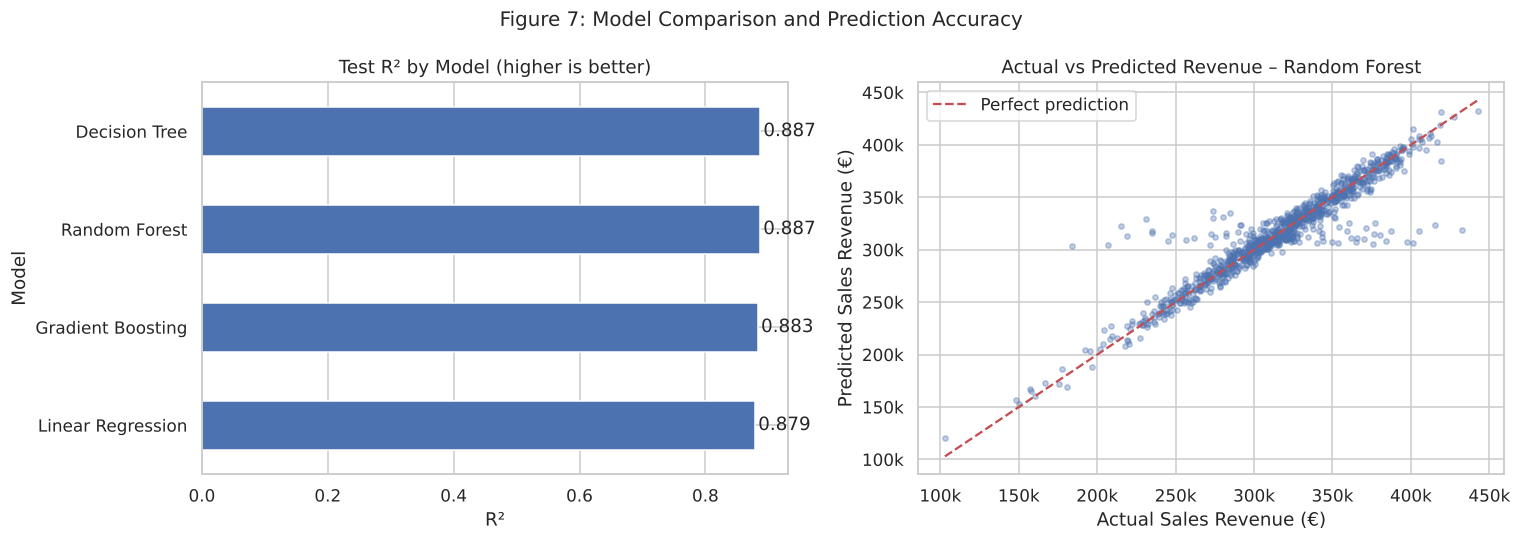

In [38]:
# Select the best model on 5-fold cross-validated R² (more reliable than a single test split)
best_name = results_df.drop("Baseline (mean)")["CV_R2_mean"].idxmax()
print("Best model (highest cross-validated R²):", best_name)
print("Over-fitting check (train R² − test R²):")
print((results_df["R2_train"] - results_df["R2_test"]).drop("Baseline (mean)").round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_df = results_df.drop("Baseline (mean)")
plot_df["R2_test"].sort_values().plot(kind="barh", ax=axes[0], color="#4C72B0")
axes[0].set_title("Test R² by Model (higher is better)")
axes[0].set_xlabel("R²")
for i, v in enumerate(plot_df["R2_test"].sort_values()):
    axes[0].text(v + 0.005, i, f"{v:.3f}", va="center")

axes[1].scatter(y_test, preds[best_name], alpha=0.35, s=12)
lims = [y_test.min(), y_test.max()]
axes[1].plot(lims, lims, "r--", label="Perfect prediction")
axes[1].set_title(f"Actual vs Predicted Revenue – {best_name}")
axes[1].set_xlabel("Actual Sales Revenue (€)")
axes[1].set_ylabel("Predicted Sales Revenue (€)")
axes[1].legend()
for a in (axes[1].xaxis, axes[1].yaxis):
    a.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x/1000:,.0f}k"))
fig.suptitle("Figure 7: Model Comparison and Prediction Accuracy", fontsize=13)
plt.tight_layout()
plt.savefig(FIG_DIR + "t1_fig07_model_comparison.png", bbox_inches="tight")
plt.show()

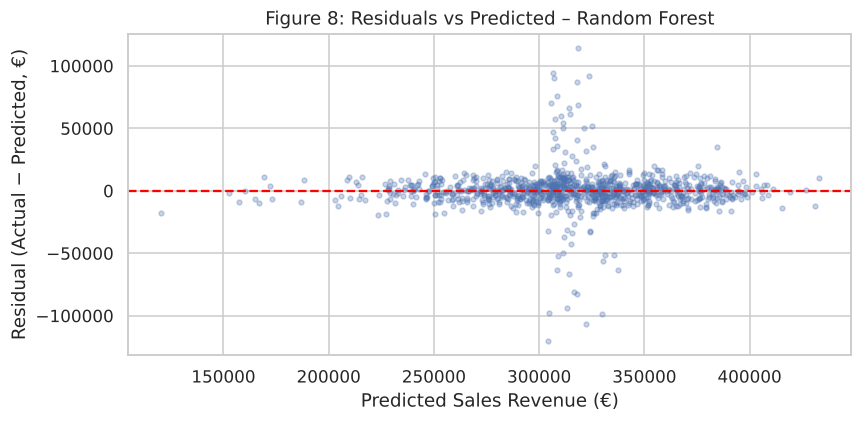

Mean residual: €19; 90% of test errors within ±€14,145


In [39]:
# Residual check for the best model – are errors random or is there a pattern?
resid = y_test - preds[best_name]
fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(preds[best_name], resid, alpha=0.3, s=10)
ax.axhline(0, color="red", ls="--")
ax.set_title(f"Figure 8: Residuals vs Predicted – {best_name}")
ax.set_xlabel("Predicted Sales Revenue (€)")
ax.set_ylabel("Residual (Actual − Predicted, €)")
plt.tight_layout()
plt.savefig(FIG_DIR + "t1_fig08_residuals.png", bbox_inches="tight")
plt.show()
print(f"Mean residual: €{resid.mean():,.0f}; 90% of test errors within ±€{resid.abs().quantile(0.9):,.0f}")

**Validation check:** the actual-vs-predicted plot shows a horizontal band of points predicted near the average. Are these the rows where MarketingSpend was missing and had to be imputed?

In [40]:
imputed_test = df.loc[X_test.index, "MarketingSpend_imputed"].astype(bool)
err_check = pd.DataFrame({
    "Rows": [(~imputed_test).sum(), imputed_test.sum()],
    "MAE": [resid[~imputed_test].abs().mean(), resid[imputed_test].abs().mean()],
    "R2": [r2_score(y_test[~imputed_test], preds[best_name][~imputed_test]),
           r2_score(y_test[imputed_test], preds[best_name][imputed_test])],
}, index=["MarketingSpend recorded", "MarketingSpend imputed"])
err_check

,Rows,MAE,R2
MarketingSpend recorded,916,"5,709.53",0.98
MarketingSpend imputed,84,"39,441.63",-0.02


### 6.4 Linear Regression coefficients (interpretable view of drivers)
Numeric features are standardised, so each coefficient is the € change in revenue for a **one standard-deviation** increase in that feature (categorical coefficients are relative to the dropped baseline level).

In [41]:
lr_pipe = fitted["Linear Regression"]
feat_names = lr_pipe.named_steps["prep"].get_feature_names_out()
coef = pd.Series(lr_pipe.named_steps["model"].coef_, index=feat_names)
coef.index = coef.index.str.replace("num__", "").str.replace("cat__", "")
coef_df = coef.sort_values(key=abs, ascending=False).to_frame("Coefficient (€ per 1 SD)")
coef_df.to_csv(TABLE_DIR + "t1_linear_coefficients.csv")
display(coef_df)

# Convert the MarketingSpend coefficient back to "€ revenue per €1 of marketing"
mkt_sd = X_train["MarketingSpend"].std(ddof=0)
print(f"Linear model: each extra €1 of marketing spend is associated with "
      f"€{coef['MarketingSpend'] / mkt_sd:,.2f} of extra revenue (holding other factors constant).")

,Coefficient (€ per 1 SD)
MarketingSpend,"46,596.99"
OnlineShare,"-2,456.44"
OnlineTraffic,"2,113.39"
MarketingPerVisitor,"-1,909.91"
TotalTraffic,"1,827.74"
Footfall,"-1,771.97"
Region_North,"-1,679.93"
CustomerSatisfaction,"1,644.48"
StoreType_Town,"-1,438.78"
InventoryAvailability,996.36


Linear model: each extra €1 of marketing spend is associated with €31.91 of extra revenue (holding other factors constant).


### 6.5 K-Means clustering – store segmentation
K-Means is used here to group the 100 stores by their average behaviour, so marketing can be targeted at segments rather than one-size-fits-all.

In [42]:
store_profile = df.groupby("StoreID").agg(
    AvgRevenue=("SalesRevenue", "mean"),
    AvgMarketingSpend=("MarketingSpend", "mean"),
    AvgFootfall=("Footfall", "mean"),
    AvgOnlineTraffic=("OnlineTraffic", "mean"),
    AvgSatisfaction=("CustomerSatisfaction", "mean"),
    AvgDiscount=("DiscountRate", "mean"),
)
scaled = StandardScaler().fit_transform(store_profile)

sil = {}
for k in range(2, 8):
    km = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit(scaled)
    sil[k] = silhouette_score(scaled, km.labels_)
pd.Series(sil, name="Silhouette score").to_frame()

,Silhouette score
2,0.22
3,0.15
4,0.17
5,0.16
6,0.14
7,0.16


In [43]:
k_best = max(sil, key=sil.get)
print("Chosen k (highest silhouette):", k_best)
km = KMeans(n_clusters=k_best, n_init=20, random_state=RANDOM_STATE).fit(scaled)
store_profile["Segment"] = km.labels_
segment_summary = store_profile.groupby("Segment").mean().round(1)
segment_summary["Stores"] = store_profile["Segment"].value_counts().sort_index()
segment_summary.to_csv(TABLE_DIR + "t1_store_segments.csv")
segment_summary

Chosen k (highest silhouette): 2


,AvgRevenue,AvgMarketingSpend,AvgFootfall,AvgOnlineTraffic,AvgSatisfaction,AvgDiscount,Stores
Segment,,,,,,,
0,"310,110.70","4,850.50","1,200.30","8,459.10",74.50,19.80,57
1,"321,088.90","5,166.20","1,208.80","8,666.10",75.60,20.10,43


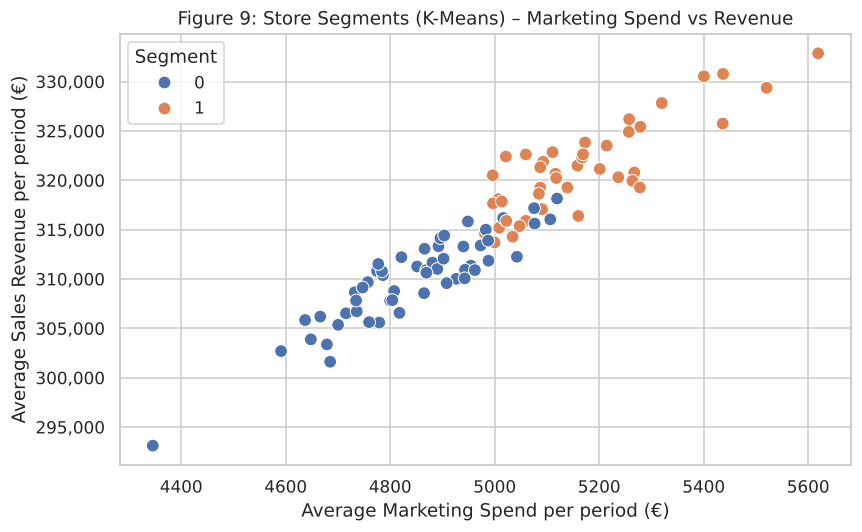

In [44]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=store_profile, x="AvgMarketingSpend", y="AvgRevenue", hue="Segment",
                palette="deep", s=70, ax=ax)
ax.set_title("Figure 9: Store Segments (K-Means) – Marketing Spend vs Revenue")
ax.set_xlabel("Average Marketing Spend per period (€)")
ax.set_ylabel("Average Sales Revenue per period (€)")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:,.0f}"))
plt.tight_layout()
plt.savefig(FIG_DIR + "t1_fig09_store_segments.png", bbox_inches="tight")
plt.show()

### 6.6 Key modelling observations
* All four models beat the naive baseline by a wide margin. Baseline MAE is ≈€37.6k; every model achieves MAE ≈€8.5k–€9.2k and R² ≈ 0.88–0.89 on unseen test data.
* **Random Forest** is selected as the best model. It has the highest cross-validated R² (≈0.90) and the lowest test MAE (≈€8.5k). The train–test gap (≈0.07) shows mild over-fitting, but cross-validation is stable (std ≈ 0.01).
* **Linear Regression performs almost as well** (R² ≈ 0.88) and is easier to explain. It estimates **≈€32 of extra revenue per extra €1 of marketing**. Since the simpler model is nearly as accurate, the relationship is mostly linear.
* **Validation finding:** most of the remaining error comes from records where MarketingSpend was missing and had to be imputed. Where spend was recorded, the model reaches R² ≈ 0.98; where it was imputed, it has no predictive power. *Complete marketing spend data is essential for forecasting.*
* **K-Means segmentation** found only weak structure (best silhouette ≈ 0.22 at k = 2). The two segments differ mainly in average marketing spend and revenue. Store behaviour is fairly homogeneous, so segmentation adds little beyond the marketing-spend finding.

## 7. Feature Importance & Marketing Insights
*(These outputs are the evidence base for the Task 3 report to the Marketing Director.)*
### 7.1 Random Forest importance vs permutation importance

In [45]:
rf_pipe = fitted["Random Forest"]
rf_imp = pd.Series(rf_pipe.named_steps["model"].feature_importances_,
                   index=rf_pipe.named_steps["prep"].get_feature_names_out())
rf_imp.index = rf_imp.index.str.replace("num__", "").str.replace("cat__", "")

# Permutation importance on the TEST set, at the original-column level (more reliable than impurity importance)
perm = permutation_importance(fitted[best_name], X_test, y_test, n_repeats=10,
                              random_state=RANDOM_STATE, scoring="r2", n_jobs=-1)
perm_imp = pd.Series(perm.importances_mean, index=X_test.columns).sort_values(ascending=False)

importance_df = pd.DataFrame({"Permutation importance (drop in R²)": perm_imp})
importance_df.to_csv(TABLE_DIR + "t1_feature_importance.csv")
importance_df

,Permutation importance (drop in R²)
MarketingSpend,1.78
OnlineTraffic,0.00
OnlineShare,0.00
Footfall,0.00
CustomerSatisfaction,0.00
StaffHours,0.00
SalesPerStaffHour,0.00
Region,0.00
PreviousMonthSales,0.00
DiscountRate,-0.00


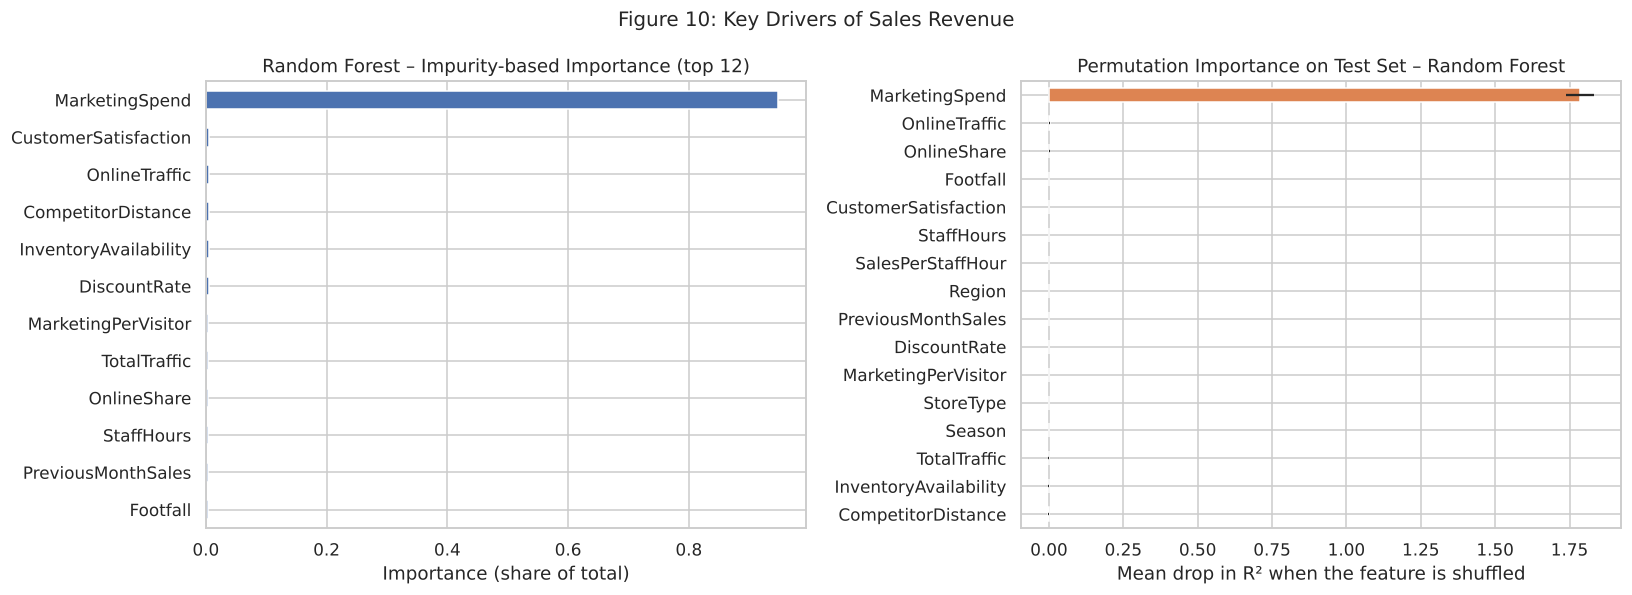

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
rf_imp.sort_values().tail(12).plot(kind="barh", ax=axes[0], color="#4C72B0")
axes[0].set_title("Random Forest – Impurity-based Importance (top 12)")
axes[0].set_xlabel("Importance (share of total)")
perm_imp.sort_values().plot(kind="barh", ax=axes[1], color="#DD8452",
                            xerr=pd.Series(perm.importances_std, index=X_test.columns)[perm_imp.sort_values().index])
axes[1].set_title(f"Permutation Importance on Test Set – {best_name}")
axes[1].set_xlabel("Mean drop in R² when the feature is shuffled")
fig.suptitle("Figure 10: Key Drivers of Sales Revenue", fontsize=13)
plt.tight_layout()
plt.savefig(FIG_DIR + "t1_fig10_feature_importance.png", bbox_inches="tight")
plt.show()

### 7.2 Diminishing returns on marketing spend
Revenue by marketing-spend decile, plus the extra revenue gained for each extra € between deciles (marginal return).

In [47]:
df["MarketingDecile"] = pd.qcut(df["MarketingSpend"], 10, labels=[f"D{i}" for i in range(1, 11)])
decile = df.groupby("MarketingDecile", observed=True).agg(
    AvgSpend=("MarketingSpend", "mean"), AvgRevenue=("SalesRevenue", "mean"))
decile["MarginalReturn_per_€"] = decile["AvgRevenue"].diff() / decile["AvgSpend"].diff()
decile.to_csv(TABLE_DIR + "t1_marketing_deciles.csv")
decile

,AvgSpend,AvgRevenue,MarginalReturn_per_€
MarketingDecile,,,
D1,"2,385.90","224,397.15",NaN
D2,"3,468.43","268,604.49",40.84
D3,"4,067.13","289,392.12",34.72
D4,"4,532.55","304,489.76",32.44
D5,"4,887.99","314,822.67",29.07
D6,"5,094.03","321,545.56",32.63
D7,"5,440.87","331,242.85",27.96
D8,"5,919.79","345,352.18",29.46
D9,"6,480.30","360,695.29",27.37


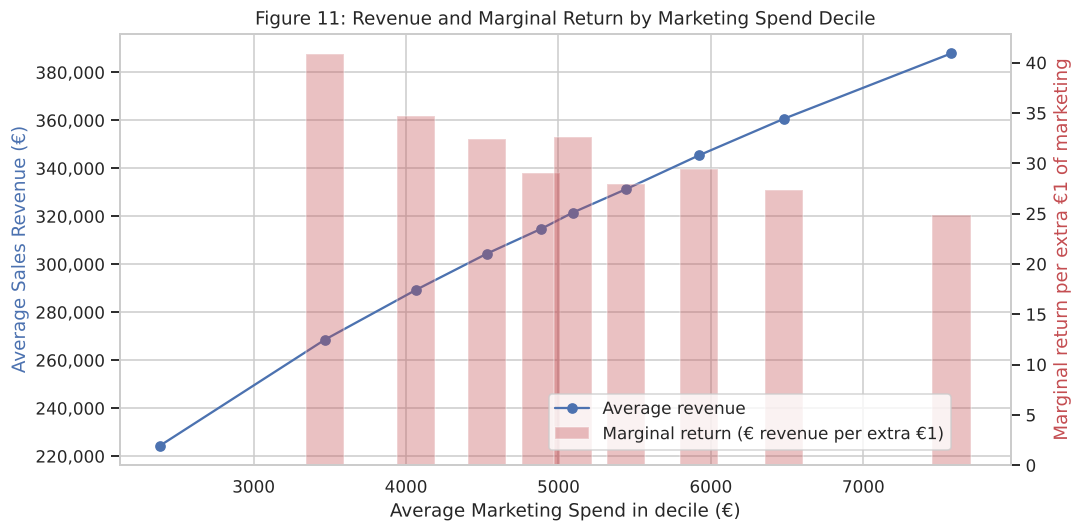

In [48]:
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.plot(decile["AvgSpend"], decile["AvgRevenue"], marker="o", color="#4C72B0", label="Average revenue")
ax1.set_xlabel("Average Marketing Spend in decile (€)")
ax1.set_ylabel("Average Sales Revenue (€)", color="#4C72B0")
ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:,.0f}"))
ax2 = ax1.twinx()
ax2.bar(decile["AvgSpend"], decile["MarginalReturn_per_€"], width=250, alpha=0.35, color="#C44E52",
        label="Marginal return (€ revenue per extra €1)")
ax2.set_ylabel("Marginal return per extra €1 of marketing", color="#C44E52")
ax2.grid(False)
fig.legend(loc="lower right", bbox_to_anchor=(0.88, 0.15))
ax1.set_title("Figure 11: Revenue and Marginal Return by Marketing Spend Decile")
plt.tight_layout()
plt.savefig(FIG_DIR + "t1_fig11_marketing_diminishing_returns.png", bbox_inches="tight")
plt.show()

### 7.3 What-if scenario – simulated effect of changing marketing spend
Using the best model, every test-set record is re-scored with marketing spend changed by ±10–30%, holding everything else constant. This gives an estimate of revenue sensitivity to the marketing budget.

In [49]:
def simulate(change):
    Xs = X_test.copy()
    Xs["MarketingSpend"] = Xs["MarketingSpend"] * (1 + change)
    Xs["MarketingPerVisitor"] = Xs["MarketingSpend"] / Xs["TotalTraffic"]
    return fitted[best_name].predict(Xs).mean()

base_rev = fitted[best_name].predict(X_test).mean()
base_spend = X_test["MarketingSpend"].mean()
scen = []
for ch in [-0.3, -0.2, -0.1, 0.1, 0.2, 0.3]:
    r = simulate(ch)
    scen.append({"SpendChange": f"{ch:+.0%}",
                 "AvgPredictedRevenue": r,
                 "RevenueChange€": r - base_rev,
                 "RevenueChange%": (r / base_rev - 1) * 100,
                 "ExtraRevenue_per_extra€": (r - base_rev) / (base_spend * ch)})
scenario_df = pd.DataFrame(scen).set_index("SpendChange")
scenario_df.to_csv(TABLE_DIR + "t1_marketing_scenarios.csv")
print(f"Baseline avg predicted revenue: €{base_rev:,.0f} at avg spend €{base_spend:,.0f}")
scenario_df

Baseline avg predicted revenue: €315,911 at avg spend €5,012


,AvgPredictedRevenue,RevenueChange€,RevenueChange%,ExtraRevenue_per_extra€
SpendChange,,,,
-30%,"267,482.95","-48,428.07",-15.33,32.21
-20%,"284,652.01","-31,259.01",-9.89,31.18
-10%,"300,766.23","-15,144.80",-4.79,30.22
+10%,"330,362.52","14,451.49",4.57,28.83
+20%,"343,770.52","27,859.50",8.82,27.79
+30%,"356,279.75","40,368.73",12.78,26.85


### 7.4 Marketing efficiency by region and store type
Where does marketing work hardest? (Median revenue per €1 of marketing spend.)

In [50]:
roi_region_type = pd.pivot_table(df, values="MarketingROI", index="Region", columns="StoreType",
                                 aggfunc="median", margins=True, margins_name="All")
roi_region_type.to_csv(TABLE_DIR + "t1_roi_region_storetype.csv")
roi_region_type

StoreType,Mall,Retail Park,Town,All
Region,,,,
East,64.24,64.79,63.56,64.20
North,63.35,64.74,62.94,63.67
South,64.21,64.93,63.79,64.36
West,64.17,62.85,62.21,63.04
All,64.06,64.37,63.19,63.82


In [51]:
# Online vs in-store: does a stronger online share relate to revenue?
df["OnlineShareBand"] = pd.qcut(df["OnlineShare"], 4, labels=["Q1 Low", "Q2", "Q3", "Q4 High"])
df.groupby("OnlineShareBand", observed=True).agg(
    AvgOnlineShare=("OnlineShare", "mean"), AvgRevenue=("SalesRevenue", "mean"),
    AvgSatisfaction=("CustomerSatisfaction", "mean"))

,AvgOnlineShare,AvgRevenue,AvgSatisfaction
OnlineShareBand,,,
Q1 Low,0.80,"311,596.26",75.06
Q2,0.86,"314,520.30",75.19
Q3,0.89,"315,277.02",74.87
Q4 High,0.92,"317,743.82",74.73


### 7.5 Key insight observations
* **Marketing spend is the dominant driver.** Shuffling it destroys the model's accuracy, while shuffling any other feature changes accuracy by less than 0.01 R². Region, season, store type, discounting, staffing and competitor distance add almost no predictive value.
* **Diminishing returns:** the marginal return falls from ≈€41 per extra €1 (D1→D2) to ≈€25 per extra €1 (D9→D10). Each extra euro still pays back many times over, but less at higher spend levels.
* **What-if scenario (Random Forest):** a **+10% marketing budget** is predicted to raise average revenue by ≈4.6% (≈€14.5k per record). A **−10% cut** is predicted to lower it by ≈4.8% (≈€15.1k).
* **Marketing efficiency is similar across locations.** Median ROI is ≈€62–€65 per €1 in every Region × StoreType cell, so there is no strong case for moving budget between regions on ROI alone.
* **Online share** has only a very small positive link with revenue: ≈€312k in the lowest quartile vs ≈€318k in the highest.
* **Data gap:** about 7% of marketing spend values were missing and about 1% were implausible. These records are where the forecasts fail.

## 8. Summary of Outputs
| Requirement | Where it is in this notebook |
|---|---|
| Missing values, duplicates, outliers, data quality summary | Section 2 (Figures 1–2) |
| ≥3 engineered features | Section 3 (7 features) |
| ≥4 GroupBy analyses + Top 5 stores/regions | Section 4 (6 GroupBys, Figure 3) |
| ≥2 Pivot tables + correlation | Section 5 (3 pivots, Figures 4–6) |
| ≥2 predictive models with train/test + MAE/RMSE/R² | Section 6 (4 regression models + K-Means, Figures 7–9) |
| Feature importance & business insight | Section 7 (Figures 10–11, scenario table) |
| ≥3 labelled visualisations | 11 figures saved to `outputs/figures/` |

All tables are exported to `outputs/tables/` so they can be referenced in the Task 3 report.